# V32: refusal descriptors failed the blind detector gate

The proposed conditional preference correction was **not fitted**. Fixed cached
post-checkpoint cohorts had sufficient detected coverage, but a blind review of
32 original training-only cases found 17 clear refusals, two ambiguous cases and
five false positives among 24 positive detections. Even the optimistic 19/24
fails the required 20/24. Eight reviewed nondetections contained no opening
refusal; this small sample does not establish recall.

The detector confuses assistant refusal with instruction compliance, fictional
dialogue, physical explanations and capability caveats. This is a feature-validity
finding, not a measured preference-loss effect. No H16 preference targets were
loaded, no residual fit, no new GPU work or official submission. Therefore no
new model/baseline quality comparison is available; the early stop is preserved.

The original float32 row-sum assertion failure is retained separately. The
correction reused the original inference probability validator without changing
predictions. Historical source inspection and domain shift remain limitations.

[Protocol](../docs/SPAN_032_PLAN.md) · [Result](../docs/SPAN_032_RESULTS.md).
The rank objective remains 19 or better on the actual official leaderboard.

,rows,one_sided,a_only,b_only,both,neither,one_sided_fraction
learning,1024,88,41,47,24,912,0.085938
confirmation,1024,72,36,36,16,936,0.070312


Successful preparation seconds/RSS GiB: 3.469637273112312 0.9912452697753906
Detector gate: False ; decision: stop_detector_before_fitting
Clear precision: 0.7083333333333334 ; optimistic precision: 0.7916666666666666
Required true positives: 20 of 24
Annotation uncertainty: One reviewer; ambiguities retained. Even both ambiguous positives counted as correct yield19<20 required. Negative sample does not estimate recall.


,false_positive_category
0,Instruction compliance: agrees not to mention ...
1,Physical visibility explanation using generic ...
2,"Quoted fictional dialogue, not an assistant re..."
3,"Riddle explanation about an abstract moment, n..."
4,Answers the language question; subsequent mach...


,ambiguous_category
0,"Answers a wordplay riddle, then declines an ex..."
1,"Explains the liar paradox, then says it cannot..."


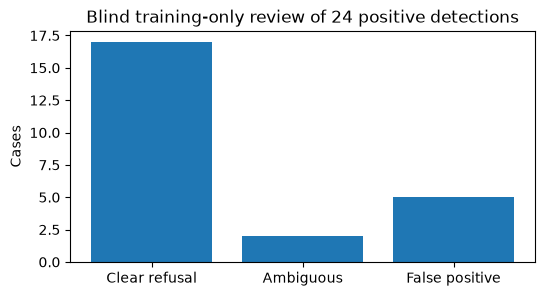

preparation_assertion_failure.json {'at': '2026-11-09T08:38:04.676082+00:00', 'session_id': 86872, 'exit_code': 1, 'stage': 'label_free_preparation', 'targets_loaded': False, 'fitting_performed': False, 'original_source_path': '/home/tarstars/database/llm_classification_finetuning/runs/span_032/prepare_before_float32_fix.py', 'original_source_sha256': 'c87b4bb768ece4f098ff57554c6a682da137b4d65c1efdc32fe3b0683cdfb4b5', 'check': 'np.testing.assert_allclose(base.sum(1),1,atol=1e-12) with default rtol=1e-7', 'maximum_float32_row_sum_error': 1.1920928955078125e-07, 'violations': 44, 'rows': 1024, 'correction': 'Reuse unchanged arena.span011_calibration.validate_probabilities: original pipeline atol1e-5. No probability/input/target/numerical model changes.'}
resource_close.json {'at': '2026-11-09T08:43:45.106202+00:00', 'passed': True, 'quota': {'used_seconds': 36651.064, 'reserved_seconds': 0.0, 'allowed_seconds': 108000.0, 'refresh_time': '2026-11-14 00:00:00', 'paid_scaling': False, 'rema

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_032'
prep=json.loads((PUB/'preparation.json').read_text())
audit=json.loads((PUB/'detector_audit.json').read_text())
coverage=pd.DataFrame(prep['coverage']).T
coverage['one_sided_fraction']=coverage.one_sided/coverage.rows
display(coverage)
print('Successful preparation seconds/RSS GiB:',prep['cpu_elapsed_seconds'],prep['peak_rss_gib'])
print('Detector gate:',audit['detector_gate_passed'],'; decision:',audit['decision'])
print('Clear precision:',audit['clear_precision'],'; optimistic precision:',audit['optimistic_precision'])
print('Required true positives:',audit['required_true_positives'],'of',audit['audited_positive'])
print('Annotation uncertainty:',audit['annotation_uncertainty'])
display(pd.DataFrame({'false_positive_category':audit['false_positive_categories']}))
display(pd.DataFrame({'ambiguous_category':audit['ambiguous_categories']}))
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(['Clear refusal','Ambiguous','False positive'],[audit['clear_refusals'],audit['ambiguous'],audit['false_positives']])
ax.set(ylabel='Cases',title='Blind training-only review of 24 positive detections')
plt.show()
for name in ['preparation_assertion_failure.json','resource_close.json','final_leaderboard.json']:
 p=PUB/name
 if p.exists():print(name,json.loads(p.read_text()))
print('No new log loss, accuracy, calibration or class-prior/hard-majority metrics: stop occurred before H16 labels/fitting. Do not substitute a different evaluation.')